# In-class Competition Tutorial
This NOTEBOOK will provide an introduction to the process of creating forecast results and the basic methodology.

First, let's review the task we will be performing (see README.ipynb for details).

**Objective**: To predict the probability of default based on customer data.

**Evaluation metric**: ROC-AUC (Area Under the Receiver Operating Characteristic Curve)

## Contents
- [1.Setup](#scrollTo=a5KcDAE8CnmB)
- [2.Loading the Data](#scrollTo=tp0cW0CD11Hi&line=1&uniqifier=1)
- [3.Visualizing and Understanding the Data](#scrollTo=3NuP1zcmCnmF&line=1&uniqifier=1)
- [4.Preprocessing and Feature Creation](#scrollTo=rsPYkguwCnmO&line=1&uniqifier=1)
- [5.Building the Machine Learning Model](#scrollTo=FoKdK60PCnmP&line=1&uniqifier=1)
- [6.Creating prediction results](#scrollTo=tn_kdvWYCnmQ&line=2&uniqifier=1)

## 1.Setup

In [1]:
# Mount Google Drive if running in Google Colaboratory
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass


### 1.1 Import Libraries
Let's load basic libraries.
Other required libraries will be loaded when we explain them.
- numpy: Library for efficient numerical computation
- pandas: Library useful for data analysis
- matplotlib: Graph drawing library
- seaborn: Graph drawing library as well

In [2]:
# Importing libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

### 1.2 Connect with Google Drive (or Local Workspace)
To load the data:
- If you are working on **Google Colaboratory**, run the cells below to connect Google Drive and navigate to the project directory.
- If you are working **locally** (VS Code, JupyterLab, etc.), the mounting step is automatically skipped, and the current project folder is used.


In [3]:
# Connect with Google Drive (auto-detects Colab vs Local)
import sys
import os
from pathlib import Path

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    print('Running on Google Colaboratory. Mounting Google Drive...')
    from google.colab import drive
    drive.mount('/content/drive')
else:
    print('Running locally. Google Drive mount skipped.')


Running locally. Google Drive mount skipped.


Next, we set the working directory where the `competition` folder is located:

- **On Google Colab**: Update `colab_competition_dir` below if your folder path is different.
- **On Local**: The current local project directory is used automatically without needing `%cd`.


In [4]:
# Set working directory for Google Colab or Local
if IN_COLAB:
    # Specify the directory where this notebook is located in Google Drive
    colab_competition_dir = Path('/content/drive/MyDrive/Competition')
    if colab_competition_dir.exists():
        os.chdir(colab_competition_dir)
        print(f'Working directory set to: {colab_competition_dir}')
    else:
        print(f'Warning: {colab_competition_dir} not found. Please verify your folder path on Google Drive.')
else:
    print(f'Using local working directory: {os.getcwd()}')


Using local working directory: d:\codingProject\OMNICAMPUS\Competition-20261003T115701Z-1-001\Competition


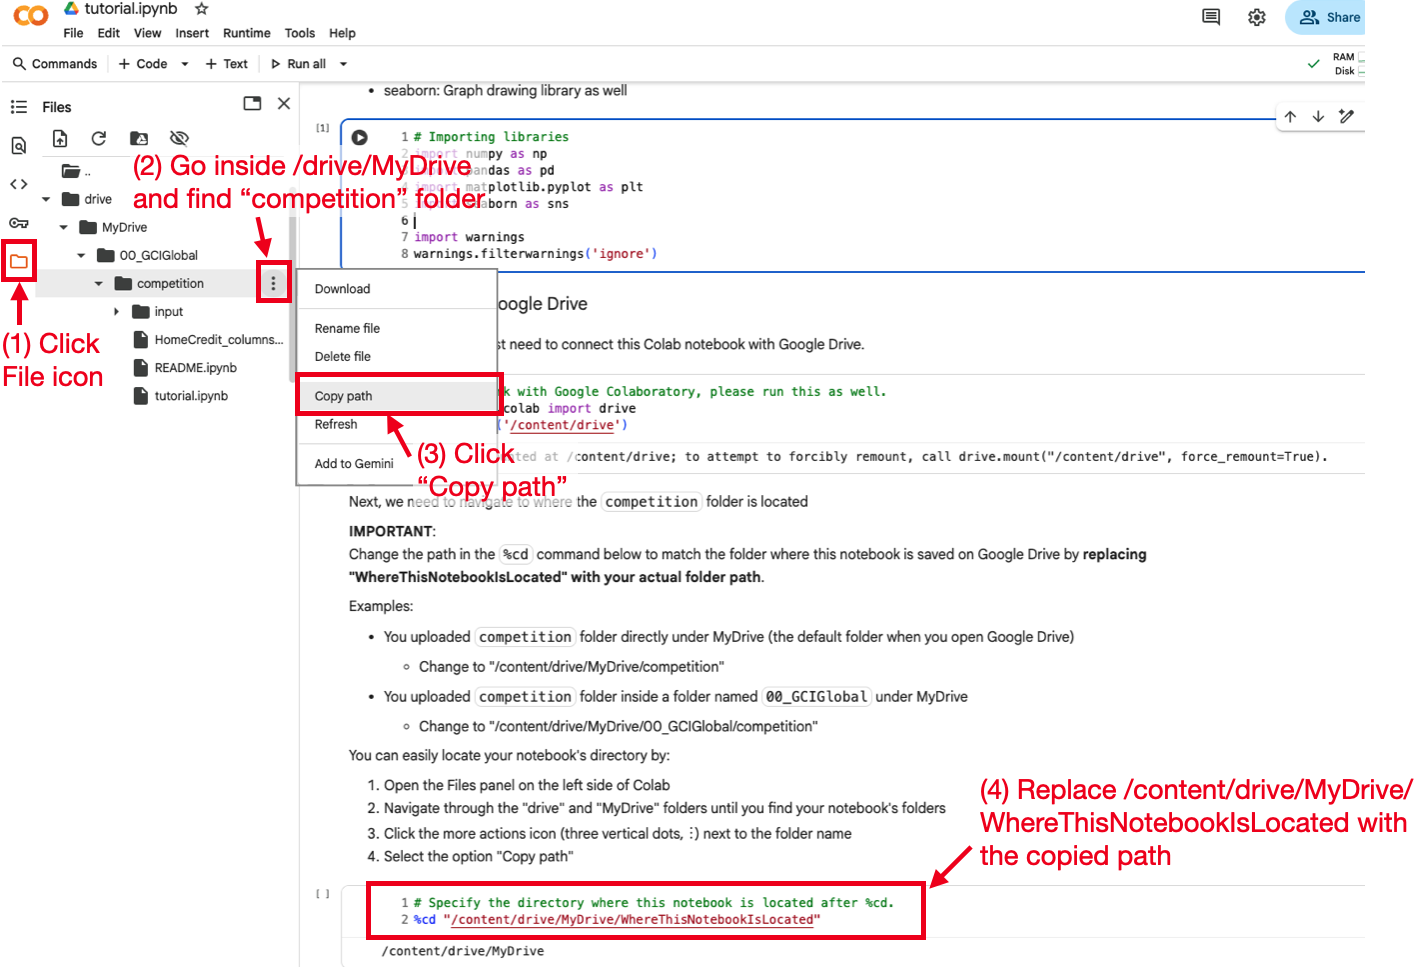

Run the cell below to check if the path is correctly set.

In [5]:
import os
from pathlib import Path

# Automatically get the current working directory
current_dir = Path(os.getcwd())

# Define file paths using pathlib
train_file = current_dir / 'input' / 'train.csv'
test_file = current_dir / 'input' / 'test.csv'
sample_sub_file = current_dir / 'input' / 'sample_submission.csv'

# Check if path exists
if train_file.exists() and test_file.exists() and sample_sub_file.exists():
    print('All files exist and path is correctly set.')
    print(f'  train: {train_file}')
    print(f'  test: {test_file}')
    print(f'  sample_submission: {sample_sub_file}')
else:
    print('Some files are missing or path is not correctly set.')
    for name, fpath in [('train', train_file), ('test', test_file), ('sample_sub', sample_sub_file)]:
        status = 'Found' if fpath.exists() else 'MISSING'
        print(f'  [{status}] {name}: {fpath}')


All files exist and path is correctly set.
  train: d:\codingProject\OMNICAMPUS\Competition-20261003T115701Z-1-001\Competition\input\train.csv
  test: d:\codingProject\OMNICAMPUS\Competition-20261003T115701Z-1-001\Competition\input\test.csv
  sample_submission: d:\codingProject\OMNICAMPUS\Competition-20261003T115701Z-1-001\Competition\input\sample_submission.csv


## 2.Loading the Data

### 2.1 Data Overview
Run the cell to load the dataset as `pd.DataFrame`.

**IMPORTANT:**<br>
**When you make modifications to preprocessing or model training, always make sure to run all cells from this cell.**

In [6]:
train = pd.read_csv(train_file)
test = pd.read_csv(test_file)
sample_sub = pd.read_csv(sample_sub_file)

Before conducting a full-scale analysis, we will first review a brief overview of the data.

In [7]:
# Check train data
print(f"train shape: {train.shape}")
train.head(3)

train shape: (171202, 34)


,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,...,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,TARGET
0,0,Cash loans,F,0,112500.0,755190.0,36328.5,675000.0,Working,Higher education,...,School,NaN,0.372591,NaN,-292.0,NaN,NaN,NaN,NaN,0
1,1,Cash loans,F,0,225000.0,585000.0,16893.0,585000.0,Pensioner,Secondary / secondary special,...,XNA,NaN,0.449567,0.553165,-617.0,0.0,0.0,0.0,1.0,0
2,2,Cash loans,F,0,54000.0,334152.0,18256.5,270000.0,State servant,Secondary / secondary special,...,Postal,NaN,0.569503,NaN,-542.0,NaN,NaN,NaN,NaN,0


In [8]:
# Check test data
print(f"test shape: {test.shape}")
test.head(3)

test shape: (61500, 33)


,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,...,REGION_RATING_CLIENT,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,171202,Cash loans,F,1,144000.0,961146.0,28233.0,688500.0,Working,Higher education,...,2,Kindergarten,NaN,0.720416,NaN,-1.0,NaN,NaN,NaN,NaN
1,171203,Cash loans,F,0,103500.0,296280.0,16069.5,225000.0,Working,Secondary / secondary special,...,2,School,NaN,0.287306,NaN,-212.0,NaN,NaN,NaN,NaN
2,171204,Cash loans,F,1,180000.0,183694.5,11236.5,139500.0,Commercial associate,Secondary / secondary special,...,3,Trade: type 7,NaN,0.352456,0.389339,-428.0,0.0,1.0,1.0,1.0


Excluding the `TARGET` column in train data and the `SK_ID_CURR` which represents ID number, you can see that there are 32 types of features.

### 2.2 Selecting Features

It is often difficult to perform data analysis and preprocessing on all features from the beginning. Instead, an easier way to get started is to start with a small number of features and then add features one by one.

This notebook will focus on 5 features. For the remaining 25 types of features, please refer to the lecture materials, the methods introduced in this notebook, etc., and perform the analysis on your own.

Feel free to also ask questions in lectures, office hours, or in the Slack community!

In [9]:
# Select predictive features based on HomeCredit_columns_description.xlsx
use_features = [
    # Baseline 5 features
    'NAME_CONTRACT_TYPE',
    'AMT_INCOME_TOTAL',
    'EXT_SOURCE_2',
    'OWN_CAR_AGE',
    'ORGANIZATION_TYPE',
    # Additional demographic, financial, and bureau features
    'CODE_GENDER',
    'CNT_CHILDREN',
    'AMT_CREDIT',
    'AMT_ANNUITY',
    'AMT_GOODS_PRICE',
    'NAME_INCOME_TYPE',
    'NAME_EDUCATION_TYPE',
    'NAME_FAMILY_STATUS',
    'NAME_HOUSING_TYPE',
    'REGION_POPULATION_RELATIVE',
    'DAYS_BIRTH',
    'DAYS_EMPLOYED',
    'DAYS_REGISTRATION',
    'DAYS_ID_PUBLISH',
    'FLAG_MOBIL',
    'FLAG_EMP_PHONE',
    'FLAG_WORK_PHONE',
    'OCCUPATION_TYPE',
    'CNT_FAM_MEMBERS',
    'REGION_RATING_CLIENT',
    'EXT_SOURCE_1',
    'EXT_SOURCE_3',
    'DAYS_LAST_PHONE_CHANGE',
    'AMT_REQ_CREDIT_BUREAU_HOUR',
    'AMT_REQ_CREDIT_BUREAU_MON',
    'AMT_REQ_CREDIT_BUREAU_QRT',
    'AMT_REQ_CREDIT_BUREAU_YEAR',
]
target = train['TARGET'].values

train = train[use_features]
train['TARGET'] = target
test = test[use_features]


Let's check the data once again.

In [10]:
# Check train data
print(f"train shape: {train.shape}")
train.head(3)

train shape: (171202, 33)


,NAME_CONTRACT_TYPE,AMT_INCOME_TOTAL,EXT_SOURCE_2,OWN_CAR_AGE,ORGANIZATION_TYPE,CODE_GENDER,CNT_CHILDREN,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,...,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,EXT_SOURCE_1,EXT_SOURCE_3,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,TARGET
0,Cash loans,112500.0,0.372591,NaN,School,F,0,755190.0,36328.5,675000.0,...,2.0,2,NaN,NaN,-292.0,NaN,NaN,NaN,NaN,0
1,Cash loans,225000.0,0.449567,NaN,XNA,F,0,585000.0,16893.0,585000.0,...,2.0,2,NaN,0.553165,-617.0,0.0,0.0,0.0,1.0,0
2,Cash loans,54000.0,0.569503,NaN,Postal,F,0,334152.0,18256.5,270000.0,...,2.0,2,NaN,NaN,-542.0,NaN,NaN,NaN,NaN,0


In [11]:
# Check test data
print(f"test shape: {test.shape}")
test.head(3)

test shape: (61500, 32)


,NAME_CONTRACT_TYPE,AMT_INCOME_TOTAL,EXT_SOURCE_2,OWN_CAR_AGE,ORGANIZATION_TYPE,CODE_GENDER,CNT_CHILDREN,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,...,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,EXT_SOURCE_1,EXT_SOURCE_3,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,Cash loans,144000.0,0.720416,NaN,Kindergarten,F,1,961146.0,28233.0,688500.0,...,Medicine staff,3.0,2,NaN,NaN,-1.0,NaN,NaN,NaN,NaN
1,Cash loans,103500.0,0.287306,NaN,School,F,0,296280.0,16069.5,225000.0,...,Cleaning staff,2.0,2,NaN,NaN,-212.0,NaN,NaN,NaN,NaN
2,Cash loans,180000.0,0.352456,NaN,Trade: type 7,F,1,183694.5,11236.5,139500.0,...,Other,2.0,3,NaN,0.389339,-428.0,0.0,1.0,1.0,1.0


### **[Next Steps]**
> + Try adding more features, starting with the ones that you think are more relevant for predicting default probability. Check `HomeCredit_columns_description.xlsx` to understand what each column represents.
> + When you add new features, always restart from [Section 2.1](#scrollTo=2TTHzi1c3a5E&line=5&uniqifier=1) by reloading the dataset.

## 3.Visualizing and Understanding the Data

The first thing we need to do before building the machine learning model is to **understand the data**. We do this by visualizing and analyzing, to deepen our understanding of data distribution, missing values, outliers, correlations, and etc. The results of the analysis obtained at this stage will be useful for preprocessing, feature creation, and selection of machine learning models, which are all important to building models with better prediction ability.

### 3.1 Checking missing values
In this section, we check for missing values.
This is important as **most machine learning models cannot be trained on data with missing values**. If there are missing values, they need to be filled with some value.

In [12]:
# Check missing values and percentages for all features in train data
missing_train = train.isnull().sum()
missing_pct = 100 * missing_train / len(train)
missing_df = pd.DataFrame({'Missing_Count': missing_train, 'Missing_Percent(%)': missing_pct})
missing_df[missing_df['Missing_Count'] > 0].sort_values(by='Missing_Count', ascending=False)


,Missing_Count,Missing_Percent(%)
EXT_SOURCE_1,118928,69.466478
OWN_CAR_AGE,112992,65.999229
EXT_SOURCE_3,54586,31.883973
AMT_REQ_CREDIT_BUREAU_QRT,23116,13.502179
AMT_REQ_CREDIT_BUREAU_HOUR,23116,13.502179
AMT_REQ_CREDIT_BUREAU_YEAR,23116,13.502179
AMT_REQ_CREDIT_BUREAU_MON,23116,13.502179
EXT_SOURCE_2,369,0.215535
CNT_FAM_MEMBERS,2,0.001168


In [13]:
# Check missing values of test data
test.isnull().sum()

NAME_CONTRACT_TYPE                0
AMT_INCOME_TOTAL                  0
EXT_SOURCE_2                    130
OWN_CAR_AGE                   40909
ORGANIZATION_TYPE                 0
CODE_GENDER                       0
CNT_CHILDREN                      0
AMT_CREDIT                        0
AMT_ANNUITY                       0
AMT_GOODS_PRICE                   0
NAME_INCOME_TYPE                  0
NAME_EDUCATION_TYPE               0
NAME_FAMILY_STATUS                0
NAME_HOUSING_TYPE                 0
REGION_POPULATION_RELATIVE        0
DAYS_BIRTH                        0
DAYS_EMPLOYED                     0
DAYS_REGISTRATION                 0
DAYS_ID_PUBLISH                   0
FLAG_MOBIL                        0
FLAG_EMP_PHONE                    0
FLAG_WORK_PHONE                   0
OCCUPATION_TYPE                   0
CNT_FAM_MEMBERS                   0
REGION_RATING_CLIENT              0
EXT_SOURCE_1                  42912
EXT_SOURCE_3                  19690
DAYS_LAST_PHONE_CHANGE      

We found that there are missing values in `EXT_SOURCE_2` and `OWN_CAR_AGE`. We will deal with these missing values later. Of course, there is a possibility that there are missing values for other features that we are not covering here, so please check them by yourself.

**Findings**:<br>
* Need to deal with missing values in `EXT_SOURCE_2` and `OWN_CAR_AGE`

### 3.2 Visualization and analysis of each feature
In this section, we visualize each feature and analyze to see what kind of characteristics it has.

#### TARGET column

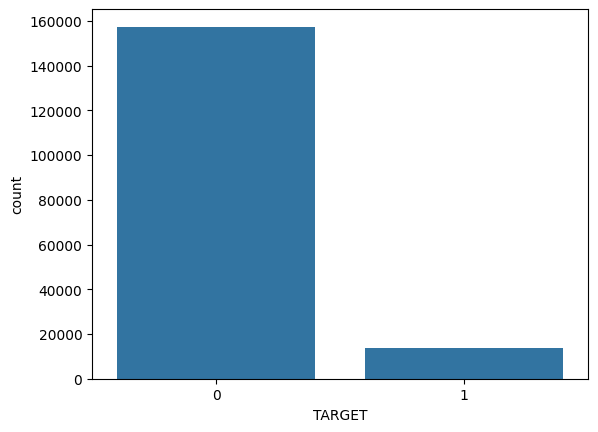

In [14]:
# The distribution of the target (default or not)
sns.countplot(data=train, x="TARGET")
plt.show()

We can see that the **distribution of the objective variable is highly skewed**: approximately **91.9% are non-default (0)** and only **8.1% are default (1)**.
Data in which the distribution of the target variable is disproportionate in this manner is called **imbalanced (or unbalanced) data**.

### How to Handle Imbalanced Data in Practice:
1. **Evaluation Metric Selection (ROC-AUC / PR-AUC)**:
   - Standard accuracy is deceptive: a trivial model predicting all zeros achieves ~92% accuracy while failing completely at identifying defaults.
   - **ROC-AUC** evaluates the model's ranking ability across all decision thresholds and is insensitive to the class ratio, making it the ideal metric for this competition.
2. **Stratified Splitting (`stratify=y` & `StratifiedKFold`)**:
   - Random splits might result in varying proportions of defaults between training and validation sets.
   - Stratified splitting guarantees that the 8.1% default rate is preserved across all training and evaluation folds.
3. **Cost-Sensitive Learning / Class Weighting**:
   - Give higher penalty weights to misclassifying the minority class.
   - In **LightGBM / XGBoost**, set `scale_pos_weight = (len(neg) / len(pos)) ~ 11.38` or calibrate via regularization.
   - In **scikit-learn** models (Logistic Regression, Random Forest), set `class_weight='balanced'`.
4. **Resampling Techniques**:
   - **Undersampling**: Randomly sub-sample the majority class.
   - **Oversampling (SMOTE / ADASYN)**: Synthesize new minority examples in feature space.
5. **Decision Threshold Tuning**:
   - In credit scoring, the default threshold of 0.5 can be lowered (e.g. to 0.2 or 0.15) to detect more potential defaults according to the lender's risk tolerance.


**Findings**:<br>
* (May) need to think about methods to mitigate the skewedness of the target variable

#### NAME_CONTRACT_TYPE column

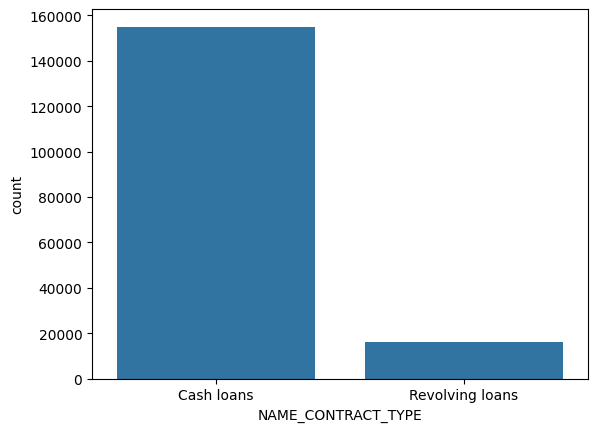

In [15]:
# The distribution of NAME_CONTRACT_TYPE
sns.countplot(data=train, x="NAME_CONTRACT_TYPE")
plt.show()

There are two variables in `NAME_CONTRACT_TYPE`, Cash loans and Revolving loans, but they are not evenly distributed. Also, since the machine learning model can only handle data of numeric type, it is necessary to convert the data from string type to numeric type.

**Findings**:<br>
* (May) need to think about methods to mitigate the skewedness of the target variable
* Need to convert the data from string type to numeric type

#### ORGANIZATION_TYPE column

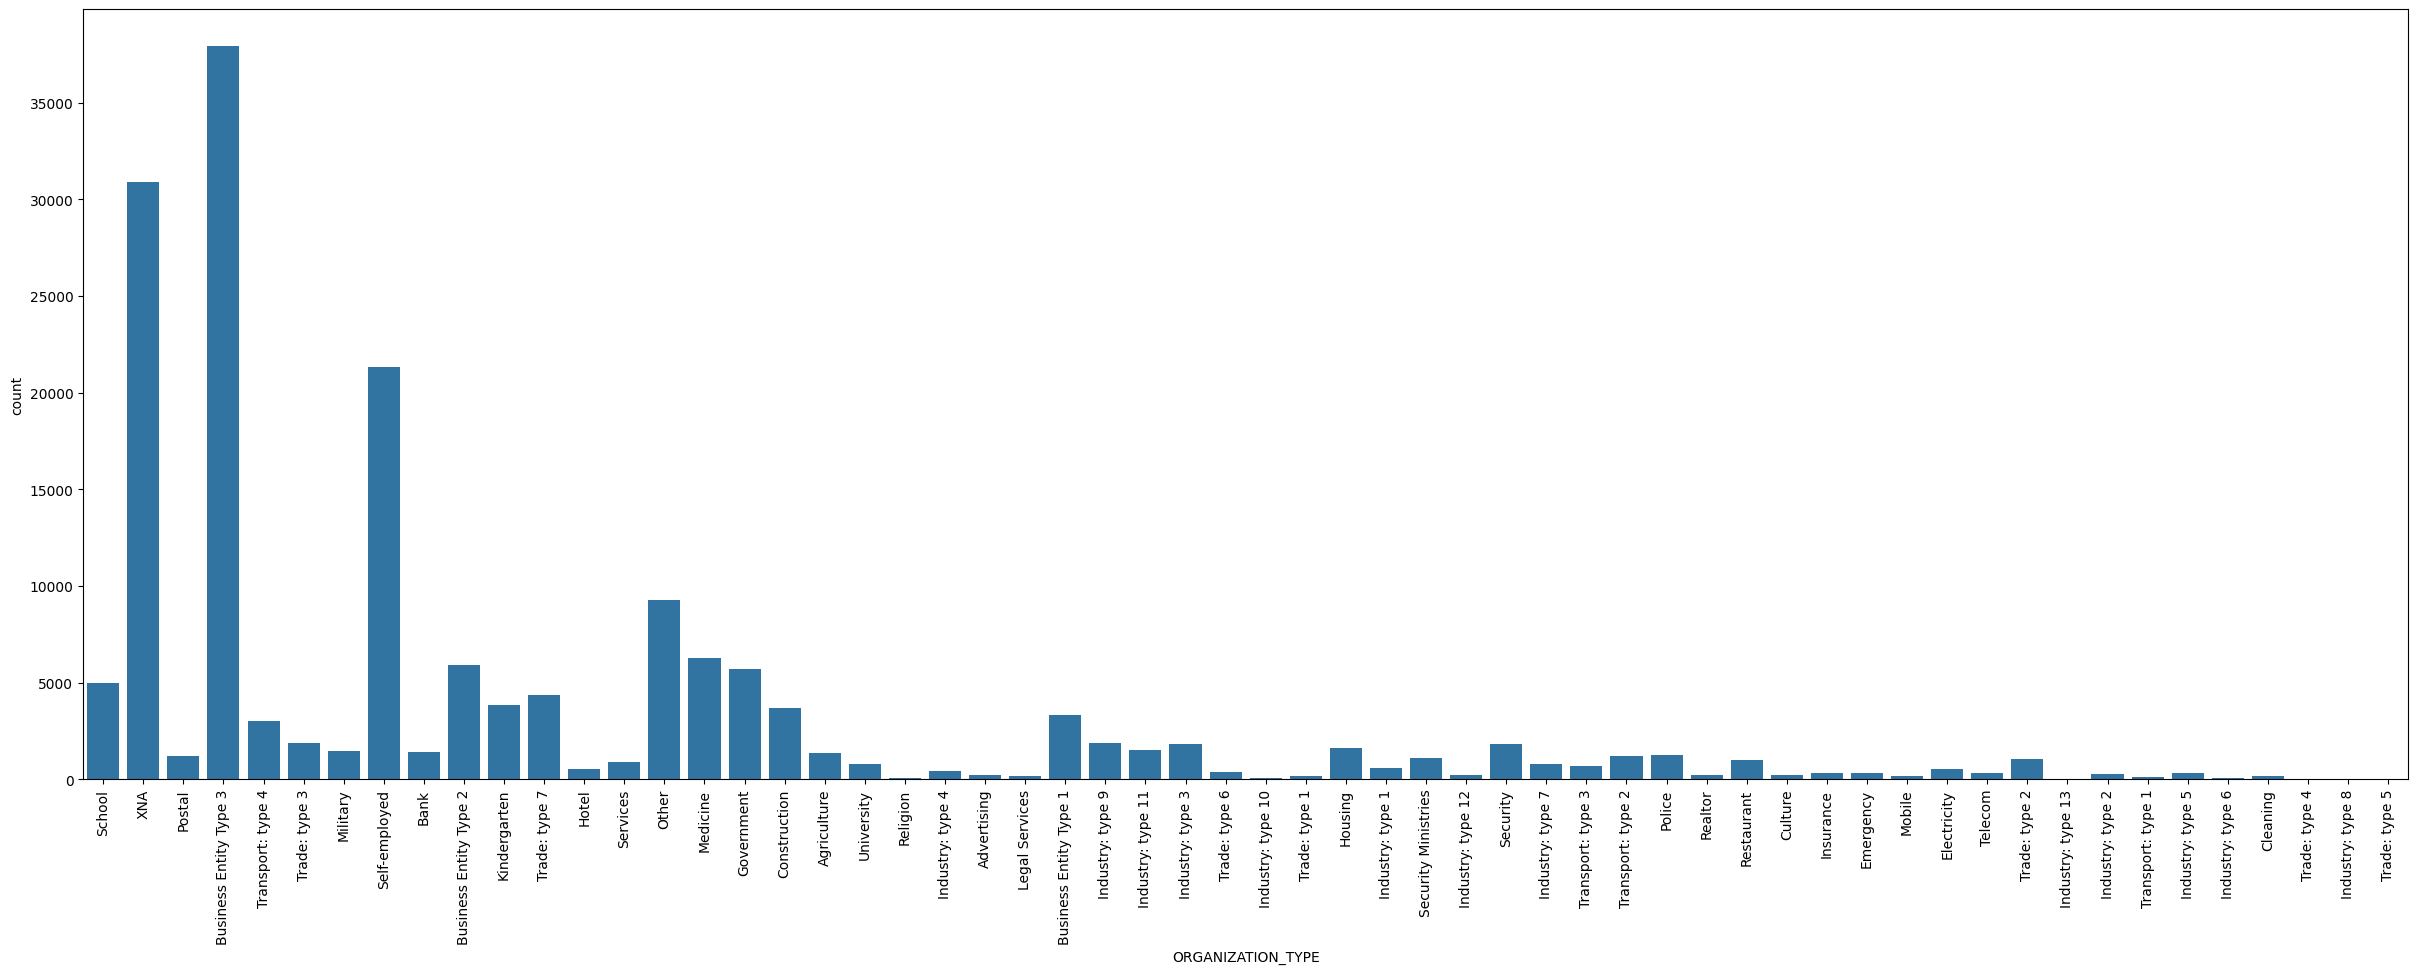

In [16]:
# The distribution of ORGANIZATION_TYPE
plt.figure(figsize=(30, 10))
sns.countplot(data=train, x="ORGANIZATION_TYPE")
plt.tick_params(axis="x", rotation=90)
plt.show()

There are many different `ORGANIZATION_TYPE`s, and you can also see that there is an ununiformity in the number of data. This is also a string type feature, so it needs to be converted to a numeric type. Also, the second variable from the left is "XNA", which we can infer from its name to be a missing value.


**Findings**:<br>
* Treat "XNA" as missing values
* Need to convert the data from string type to numeric type

#### EXT_SOURCE_2 column

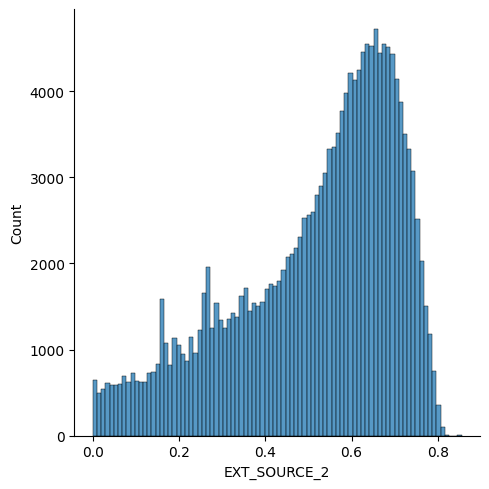

In [17]:
# The distribution of EXT_SOURCE_2
sns.displot(data=train, x="EXT_SOURCE_2")
plt.show()

We can see that EXT_SOURCE_2 is normalized between 0 and 1. It seems we can handle this feature as it is.

**Findings**:<br>
* No additional preprocessing is needed

#### AMT_INCOME_TOTAL column

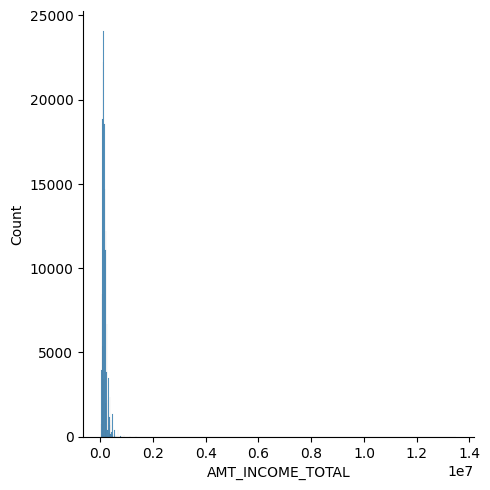

In [18]:
# The distribution of AMT_INCOME_TOTAL
sns.displot(data=train, x="AMT_INCOME_TOTAL")
plt.show()

The visualization of `AMT_INCOME_TOTAL` is hard to interpret. THis may be caused by the presence of a small number of outliers that take large values. To visualize data like this, a logarithmic transformation can be effective.

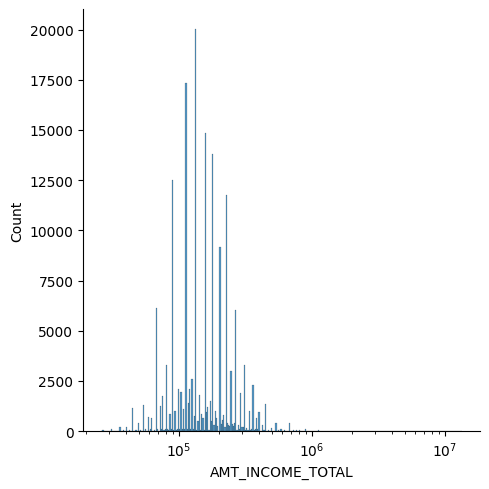

In [19]:
# The distribution of AMT_INCOME_TOTAL（Logarithmic transformation）
sns.displot(data=train, x="AMT_INCOME_TOTAL", log_scale=10)
plt.show()

We displayed the graph successfully by using logarithmic transformation.
The income is supposed to be a continuous value, but it looks like a discrete value. Let's have a look at the type of `AMT_INCOME_TOTAL` values.

In [20]:
# Check the type of AMT_INCOME_TOTAL values
len(train["AMT_INCOME_TOTAL"].unique())

1641

There are 171202 data in train, but `AMT_INCOME_TOTAL` consists of only 1641 different values. Let's check the top 10 values specifically.

In [21]:
# Top 10 values of AMT_INCOME_TOTAL
train["AMT_INCOME_TOTAL"].value_counts().head(10)

AMT_INCOME_TOTAL
135000.0    19969
112500.0    17320
157500.0    14772
180000.0    13791
90000.0     12481
225000.0    11573
202500.0     9128
67500.0      6130
270000.0     6006
81000.0      3295
Name: count, dtype: int64

It appears that `AMT_INCOME_TOTAL` is not an exact annual income, but rather data compiled from a rounded number.

**Findings**:<br>
* Should the outlier in the data be addressed?

#### OWN_CAR_AGE column

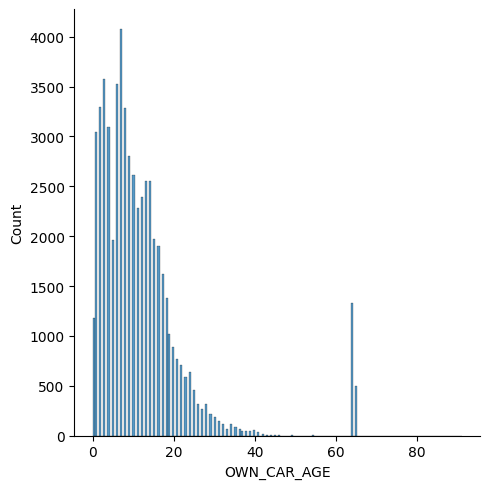

In [22]:
# The distribution of OWN_CAR_AGE
sns.displot(data=train, x="OWN_CAR_AGE")
plt.show()

`OWN_CAR_AGE` can be inferred to be in years from the scale of values. In addition, the distribution is natural from 0 to 40, but there is an unnatural distribution around 60 to 70. It is hard to imagine that the number of years a car has been purchased increases suddenly like this, so they are considered to be outliers.

**Findings**:<br>
* Treat numbers above 60 as outliers

#### EXT_SOURCE_1 and EXT_SOURCE_3 columns
Let's visualize the normalized external credit scoring bureau features (`EXT_SOURCE_1` and `EXT_SOURCE_3`) to examine how they relate to default probability.


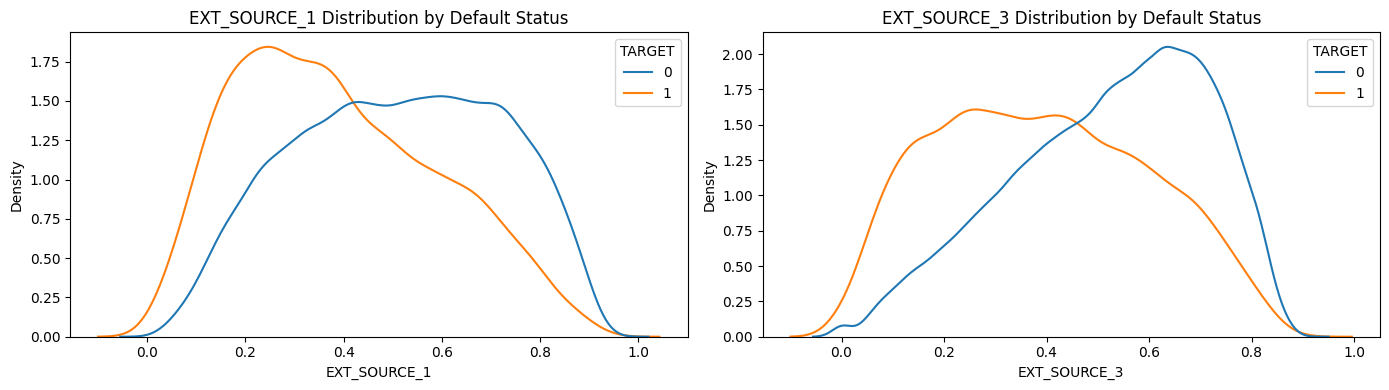

In [23]:
# Distribution of EXT_SOURCE_1 and EXT_SOURCE_3 by TARGET
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.kdeplot(data=train, x='EXT_SOURCE_1', hue='TARGET', common_norm=False, ax=axes[0])
axes[0].set_title('EXT_SOURCE_1 Distribution by Default Status')

sns.kdeplot(data=train, x='EXT_SOURCE_3', hue='TARGET', common_norm=False, ax=axes[1])
axes[1].set_title('EXT_SOURCE_3 Distribution by Default Status')
plt.tight_layout()
plt.show()


**Findings**:
- `EXT_SOURCE_1` and `EXT_SOURCE_3` show strong separation between defaulters (TARGET=1) and non-defaulters (TARGET=0).
- Clients with lower external scores exhibit significantly higher risk of default.
- Interactions (products, ratios, and averages) between external sources will provide strong predictive power.


#### Age (DAYS_BIRTH) and Employment Duration (DAYS_EMPLOYED)
`DAYS_BIRTH` and `DAYS_EMPLOYED` are negative day counts relative to the current application. Let's convert them to years and examine their distributions.


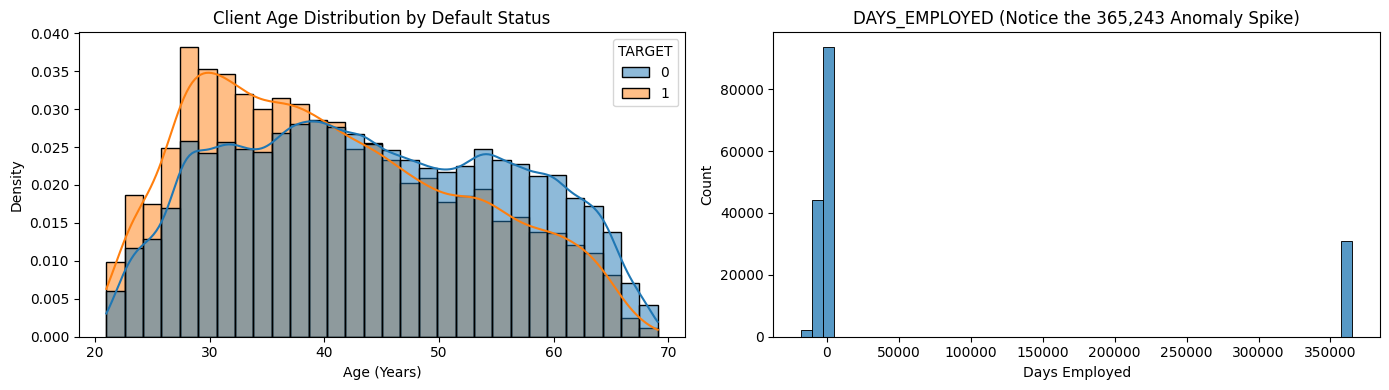

In [24]:
# Age in years and Employment distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Age in years
age_years = -train['DAYS_BIRTH'] / 365.25
sns.histplot(x=age_years, hue=train['TARGET'], bins=30, kde=True, stat='density', common_norm=False, ax=axes[0])
axes[0].set_title('Client Age Distribution by Default Status')
axes[0].set_xlabel('Age (Years)')

# DAYS_EMPLOYED anomaly check
sns.histplot(train['DAYS_EMPLOYED'], bins=50, ax=axes[1])
axes[1].set_title('DAYS_EMPLOYED (Notice the 365,243 Anomaly Spike)')
axes[1].set_xlabel('Days Employed')
plt.tight_layout()
plt.show()


**Findings**:
- Younger clients (under 35) have higher relative default rates than older clients (over 50).
- `DAYS_EMPLOYED` has an extreme anomalous spike at **365,243 days** (~1,000 years). These represent retired/unemployed individuals whose organization type is 'XNA'. We must replace `365243` with `np.nan` and add an anomaly indicator `DAYS_EMPLOYED_ANOM`.


#### Loan & Credit Features (AMT_CREDIT, AMT_ANNUITY, AMT_GOODS_PRICE)
Let's examine the distributions of loan amounts and the client payment burden.


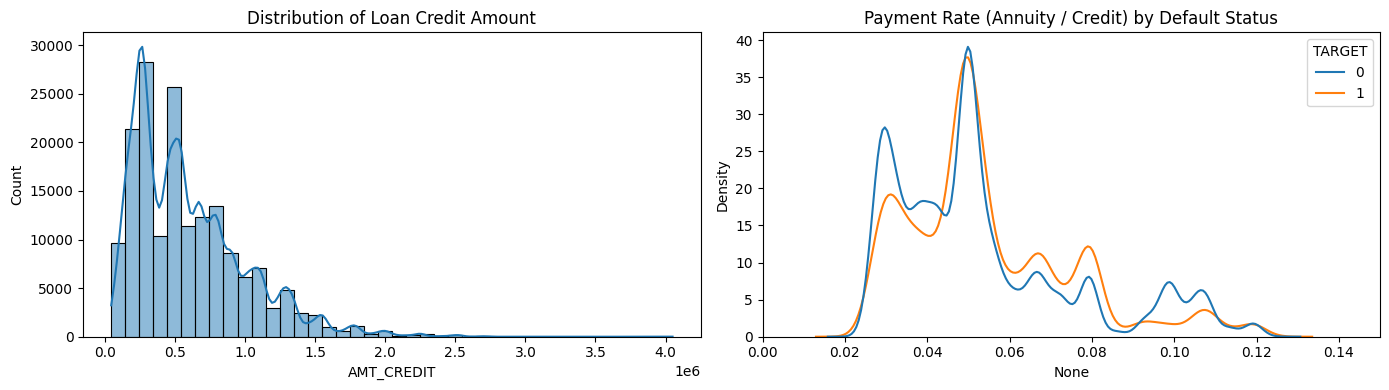

In [25]:
# Distribution of Loan Credit and Annuity
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(train['AMT_CREDIT'], bins=40, kde=True, ax=axes[0])
axes[0].set_title('Distribution of Loan Credit Amount')

# Payment rate: Annuity / Credit
payment_rate = train['AMT_ANNUITY'] / (train['AMT_CREDIT'] + 1e-6)
sns.kdeplot(x=payment_rate, hue=train['TARGET'], common_norm=False, ax=axes[1])
axes[1].set_title('Payment Rate (Annuity / Credit) by Default Status')
axes[1].set_xlim(0, 0.15)
plt.tight_layout()
plt.show()


**Findings**:
- Loan amounts and annuities are right-skewed.
- The ratio of Annuity to Credit (Payment Rate) and Credit to Income are highly predictive domain indicators of repayment stress.


#### Demographics & Categorical Attributes (CODE_GENDER, NAME_EDUCATION_TYPE, NAME_INCOME_TYPE)
Let's observe default rates across gender, education, and income categories.


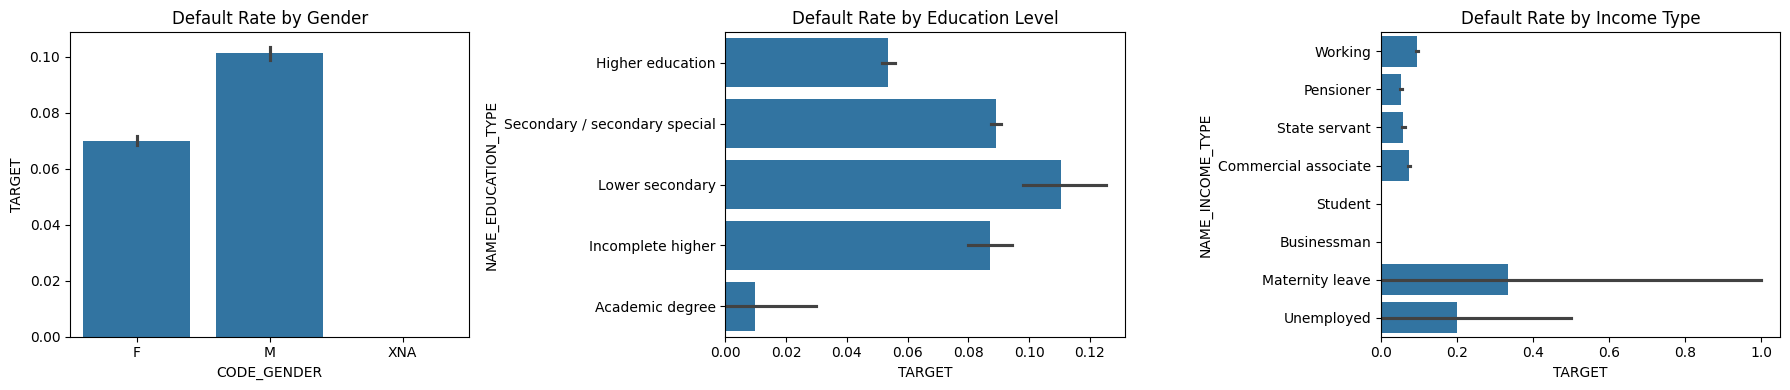

In [26]:
# Default rate across categorical attributes
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
sns.barplot(data=train, x='CODE_GENDER', y='TARGET', ax=axes[0])
axes[0].set_title('Default Rate by Gender')

sns.barplot(data=train, y='NAME_EDUCATION_TYPE', x='TARGET', ax=axes[1])
axes[1].set_title('Default Rate by Education Level')

sns.barplot(data=train, y='NAME_INCOME_TYPE', x='TARGET', ax=axes[2])
axes[2].set_title('Default Rate by Income Type')
plt.tight_layout()
plt.show()


**Findings**:
- Clients with 'Higher education' or 'Academic degree' have significantly lower default rates.
- Unemployed and Maternity leave income categories exhibit distinct default profiles.
- 'XNA' exists in small numbers in `CODE_GENDER` and must be treated as missing values.


#### Credit Bureau Inquiries (AMT_REQ_CREDIT_BUREAU_*)
Inquiries to the Credit Bureau indicate how frequently an applicant has recently sought credit.


In [27]:
# Credit bureau inquiries
bureau_cols = [c for c in train.columns if 'AMT_REQ_CREDIT_BUREAU' in c]
train[bureau_cols].describe()


,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
count,148086.000000,148086.000000,148086.000000,148086.000000
mean,0.006652,0.268418,0.267547,1.903644
std,0.086204,0.921022,0.914532,1.872237
min,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000,1.000000
75%,0.000000,0.000000,0.000000,3.000000
max,4.000000,23.000000,261.000000,23.000000


**Findings**:
- The bureau inquiry columns (`HOUR`, `MON`, `QRT`, `YEAR`) have ~13.5% missing values and can be combined into a single total inquiry feature `AMT_REQ_CREDIT_BUREAU_TOTAL`.


Up to this point, we have visualized and analyzed each feature. I believe that you have realized that visualization requires some ingenuity and that visualization can deepen your understanding of data. I am sure that the visualization and analysis of the 25 features not covered here will lead to improved forecasting accuracy.

### **[Next Steps]**
> + Check for missing values for the features you have added in Section 2.2.
> + Visualize the features you have added. Is the feature categorical or continuous? What type of graph is most effective to understand it?
> + What do you notice about the features? What kind of preprocessing is needed?

## 4.Preprocessing and Feature Creation
Here, we will conduct the preprocessing and create new features based on what we have learned in the preceding visualization and analysis.

### NAME_CONTRACT_TYPE column
Convert `NAME_CONTRACT_TYPE` to a numeric type. In this case, “Cash loans” is converted to 0 and “Revolving loans” to 1. This method of simply replacing an integer is called **Label Encoding**.

In [28]:
# Numerization of NAME_CONTRACT_TYPE (Label Encoding)
train['NAME_CONTRACT_TYPE'] = train['NAME_CONTRACT_TYPE'].replace({'Cash loans': 0, 'Revolving loans': 1}).astype(int)
test['NAME_CONTRACT_TYPE'] = test['NAME_CONTRACT_TYPE'].replace({'Cash loans': 0, 'Revolving loans': 1}).astype(int)

train.head(5)


,NAME_CONTRACT_TYPE,AMT_INCOME_TOTAL,EXT_SOURCE_2,OWN_CAR_AGE,ORGANIZATION_TYPE,CODE_GENDER,CNT_CHILDREN,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,...,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,EXT_SOURCE_1,EXT_SOURCE_3,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,TARGET
0,0,112500.0,0.372591,NaN,School,F,0,755190.0,36328.5,675000.0,...,2.0,2,NaN,NaN,-292.0,NaN,NaN,NaN,NaN,0
1,0,225000.0,0.449567,NaN,XNA,F,0,585000.0,16893.0,585000.0,...,2.0,2,NaN,0.553165,-617.0,0.0,0.0,0.0,1.0,0
2,0,54000.0,0.569503,NaN,Postal,F,0,334152.0,18256.5,270000.0,...,2.0,2,NaN,NaN,-542.0,NaN,NaN,NaN,NaN,0
3,0,67500.0,0.105235,NaN,XNA,F,0,152820.0,8901.0,135000.0,...,1.0,3,NaN,0.767523,0.0,0.0,0.0,0.0,0.0,0
4,0,157500.0,0.202490,NaN,Business Entity Type 3,M,0,271066.5,21546.0,234000.0,...,2.0,3,0.342344,0.669057,-1243.0,0.0,0.0,0.0,4.0,1


### ORGANIZATION_TYPE column
Convert `ORGANIZATION_TYPE` to a numeric type. This time, we will convert the variable to numeric in terms of the number of data in the variable. For example, if the number of data in “Police” is 1279 and the number of data in “Bank” is 1385, convert “Police” to 1279 and “Bank” to 1385. This method of replacing the number of data with the number of data is called **Count Encoding**.

In [29]:
# Numerization of ORGANIZATION_TYPE (Count Encoding）
organization_ce = train["ORGANIZATION_TYPE"].value_counts()
train["ORGANIZATION_TYPE"] = train["ORGANIZATION_TYPE"].map(organization_ce)
test["ORGANIZATION_TYPE"] = test["ORGANIZATION_TYPE"].map(organization_ce)

train.head(5)

,NAME_CONTRACT_TYPE,AMT_INCOME_TOTAL,EXT_SOURCE_2,OWN_CAR_AGE,ORGANIZATION_TYPE,CODE_GENDER,CNT_CHILDREN,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,...,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,EXT_SOURCE_1,EXT_SOURCE_3,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,TARGET
0,0,112500.0,0.372591,NaN,4991,F,0,755190.0,36328.5,675000.0,...,2.0,2,NaN,NaN,-292.0,NaN,NaN,NaN,NaN,0
1,0,225000.0,0.449567,NaN,30898,F,0,585000.0,16893.0,585000.0,...,2.0,2,NaN,0.553165,-617.0,0.0,0.0,0.0,1.0,0
2,0,54000.0,0.569503,NaN,1185,F,0,334152.0,18256.5,270000.0,...,2.0,2,NaN,NaN,-542.0,NaN,NaN,NaN,NaN,0
3,0,67500.0,0.105235,NaN,30898,F,0,152820.0,8901.0,135000.0,...,1.0,3,NaN,0.767523,0.0,0.0,0.0,0.0,0.0,0
4,0,157500.0,0.202490,NaN,37943,M,0,271066.5,21546.0,234000.0,...,2.0,3,0.342344,0.669057,-1243.0,0.0,0.0,0.0,4.0,1


### EXT_SOURCE_2 column
Missing values in `EXT_SOURCE_2` (and external sources in general) carry informative missingness signals.
Tree-based algorithms like LightGBM, XGBoost, and CatBoost have built-in branch direction logic for missing values.
Instead of arbitrarily imputing with the mean (which distorts the distribution and removes the missing signal),
we preserve missing values for tree models and create explicit missingness indicator features.

In [30]:
# Rather than mean imputation, preserve NaNs for tree models and compute missingness indicators
print(f'EXT_SOURCE_2 missing in train: {train["EXT_SOURCE_2"].isna().sum()} / {len(train)}')
print(f'EXT_SOURCE_2 missing in test:  {test["EXT_SOURCE_2"].isna().sum()} / {len(test)}')


EXT_SOURCE_2 missing in train: 369 / 171202
EXT_SOURCE_2 missing in test:  130 / 61500


### OWN_CAR_AGE column
First, we will replace the unnatural outliers that are over 60 as `np.nan` (missing values).

In [31]:
# Treat values above 60 (outliers) in OWN_CAR_AGE as missing values
train.loc[train["OWN_CAR_AGE"] >= 60, "OWN_CAR_AGE"] = np.nan
test.loc[test["OWN_CAR_AGE"] >= 60, "OWN_CAR_AGE"] = np.nan

Next, we consider the handling of missing values. The original `OWN_CAR_AGE` had 112992 missing values out of 171202 data. With such a large number of missing values, it is difficult and impractical to properly fill the missing values with some value. Therefore, we will group `OWN_CAR_AGE` by decade (e.g. Group 1: 0-9 years, Group 2: 10-19 years, etc.), then apply **One Hot Encoding**.

In [32]:
# Divide OWN_CAR_AGE into groups (preserve original OWN_CAR_AGE for ratio features)
train["OWN_CAR_AGE_GROUP"] = train["OWN_CAR_AGE"] // 10
test["OWN_CAR_AGE_GROUP"] = test["OWN_CAR_AGE"] // 10
train["OWN_CAR_AGE_GROUP"].unique()


array([nan,  0.,  2.,  1.,  3.,  4.,  5.])

In [33]:
# Apply One Hot Encoding to OWN_CAR_AGE_GROUP
train_car_age_ohe = pd.get_dummies(train["OWN_CAR_AGE_GROUP"]).add_prefix("OWN_CAR_AGE_")
test_car_age_ohe = pd.get_dummies(test["OWN_CAR_AGE_GROUP"]).add_prefix("OWN_CAR_AGE_")

# Add the one hot encoded columns to train/test
train = pd.concat([train, train_car_age_ohe], axis=1)
test = pd.concat([test, test_car_age_ohe], axis=1)

# Drop temporary group column, retaining continuous OWN_CAR_AGE for competitive ratio features
train.drop('OWN_CAR_AGE_GROUP', axis=1, inplace=True, errors='ignore')
test.drop('OWN_CAR_AGE_GROUP', axis=1, inplace=True, errors='ignore')

train.head(5)


,NAME_CONTRACT_TYPE,AMT_INCOME_TOTAL,EXT_SOURCE_2,OWN_CAR_AGE,ORGANIZATION_TYPE,CODE_GENDER,CNT_CHILDREN,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,...,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,TARGET,OWN_CAR_AGE_0.0,OWN_CAR_AGE_1.0,OWN_CAR_AGE_2.0,OWN_CAR_AGE_3.0,OWN_CAR_AGE_4.0,OWN_CAR_AGE_5.0
0,0,112500.0,0.372591,NaN,4991,F,0,755190.0,36328.5,675000.0,...,NaN,NaN,NaN,0,False,False,False,False,False,False
1,0,225000.0,0.449567,NaN,30898,F,0,585000.0,16893.0,585000.0,...,0.0,0.0,1.0,0,False,False,False,False,False,False
2,0,54000.0,0.569503,NaN,1185,F,0,334152.0,18256.5,270000.0,...,NaN,NaN,NaN,0,False,False,False,False,False,False
3,0,67500.0,0.105235,NaN,30898,F,0,152820.0,8901.0,135000.0,...,0.0,0.0,0.0,0,False,False,False,False,False,False
4,0,157500.0,0.202490,NaN,37943,M,0,271066.5,21546.0,234000.0,...,0.0,0.0,4.0,1,False,False,False,False,False,False


### 4.5 Handling Outliers, Anomalies, and Missing Values (Based on Section 3 Findings)
From our visualizations and statistical checks in Section 3, we implement targeted preprocessing:
1. **Imbalanced Data Handling**:
   - Stratified train-test split (`stratify=y`) and balanced class weighting in models (`scale_pos_weight` in LightGBM/XGBoost, `class_weight='balanced'` in linear models).
2. **Outlier and Anomaly Treatments**:
   - **Treat 'XNA' as missing values (`np.nan`)**: Discovered in `CODE_GENDER` and `ORGANIZATION_TYPE`.
   - **Handle `DAYS_EMPLOYED == 365243`**: Replace the 1,000-year anomaly with `np.nan` and create an explicit binary indicator `DAYS_EMPLOYED_ANOM`.
3. **Missing Value Imputation for Newly Added Features**:
   - Impute missing values for `EXT_SOURCE_1` and `EXT_SOURCE_3` using the training mean.
   - Median imputation for remaining continuous features.

In [34]:
# 1. Treat 'XNA' as missing values (NaN) across all features
train = train.replace('XNA', np.nan)
test = test.replace('XNA', np.nan)

# 2. Treat DAYS_EMPLOYED anomaly (365243 = pensioner/unemployed) as missing values and add indicator
train['DAYS_EMPLOYED_ANOM'] = (train['DAYS_EMPLOYED'] == 365243).astype(int)
test['DAYS_EMPLOYED_ANOM'] = (test['DAYS_EMPLOYED'] == 365243).astype(int)
train['DAYS_EMPLOYED'] = train['DAYS_EMPLOYED'].replace(365243, np.nan)
test['DAYS_EMPLOYED'] = test['DAYS_EMPLOYED'].replace(365243, np.nan)

# 3. Impute missing values for EXT_SOURCE_1 and EXT_SOURCE_3 with train means
for col in ['EXT_SOURCE_1', 'EXT_SOURCE_3']:
    col_mean = train[col].mean()
    train[col] = train[col].fillna(col_mean)
    test[col] = test[col].fillna(col_mean)


### 4.6 Advanced Competitive Feature Engineering (Kaggle Grandmaster Suite)
To maximize prediction accuracy, we implement three critical feature engineering pillars:
1. **Frequency-Encoding Interactions**: Joint frequency distributions for high-cardinality cross-interactions (e.g., `OCCUPATION_TYPE` $\times$ `ORGANIZATION_TYPE`, `EDUCATION` $\times$ `INCOME_TYPE`).
2. **Domain-Specific Missingness Clustering**: Informative missingness across external data (`MISSING_EXT`), bureau records (`MISSING_BUREAU`), and overall application profile (`MISSING_TOTAL`).
3. **Polynomial & Interaction Features across Bureau & Financials**:
   - Non-linear debt burden: `PAYMENT_RATE ** 2`, `ANNUITY_INCOME_RATIO ** 2`, `CREDIT_INCOME_RATIO ** 2`
   - Real disposable income: `AMT_INCOME_TOTAL - AMT_ANNUITY` and disposable income per family member
   - Bureau inquiry stress: Short-term inquiry burst ratio relative to yearly inquiries
   - Complete pairwise interactions, polynomial squares, and demographic cross-terms for `EXT_SOURCE_1, 2, 3`.

In [35]:
# 1. High-Cardinality Frequency-Encoding Interactions
cat_interaction_pairs = [
    ('OCCUPATION_TYPE', 'ORGANIZATION_TYPE'),
    ('NAME_EDUCATION_TYPE', 'NAME_INCOME_TYPE'),
    ('CODE_GENDER', 'NAME_EDUCATION_TYPE'),
    ('NAME_INCOME_TYPE', 'ORGANIZATION_TYPE'),
    ('NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE')
]
for c1, c2 in cat_interaction_pairs:
    if c1 in train.columns and c2 in train.columns:
        pair_train = train[c1].astype(str) + '_' + train[c2].astype(str)
        pair_test  = test[c1].astype(str) + '_' + test[c2].astype(str)
        freq = pair_train.value_counts()
        train[f'{c1}_{c2}_FREQ'] = pair_train.map(freq)
        test[f'{c1}_{c2}_FREQ']  = pair_test.map(freq)

for col in ['OCCUPATION_TYPE', 'ORGANIZATION_TYPE', 'NAME_INCOME_TYPE',
            'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE']:
    if col in train.columns:
        freq = train[col].value_counts()
        train[f'{col}_FREQ'] = train[col].map(freq)
        test[f'{col}_FREQ']  = test[col].map(freq)

# 2. Domain-Specific Missingness Clustering & Financial/Bureau Features
ext_cols = [c for c in ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3'] if c in train.columns]
bureau_cols = [c for c in train.columns if 'AMT_REQ_CREDIT_BUREAU' in c]

for df in [train, test]:
    # Missingness clusters
    df['MISSING_TOTAL']  = df.isna().sum(axis=1)
    if ext_cols:
        df['MISSING_EXT'] = df[ext_cols].isna().sum(axis=1)
    if bureau_cols:
        df['MISSING_BUREAU'] = df[bureau_cols].isna().sum(axis=1)

    # Robust handling of OWN_CAR_AGE (continuous or OHE derived)
    if 'OWN_CAR_AGE' in df.columns:
        df['OWN_CAR_FLAG'] = df['OWN_CAR_AGE'].notna().astype(int)
    else:
        car_ohe = [c for c in df.columns if 'OWN_CAR_AGE_' in c]
        df['OWN_CAR_FLAG'] = (df[car_ohe].sum(axis=1) > 0).astype(int) if car_ohe else 0

    # Financial solvency & polynomial powers
    if 'AMT_ANNUITY' in df.columns and 'AMT_CREDIT' in df.columns:
        df['PAYMENT_RATE']    = df['AMT_ANNUITY'] / (df['AMT_CREDIT'] + 1e-6)
        df['PAYMENT_RATE_SQ'] = df['PAYMENT_RATE'] ** 2
    if 'AMT_CREDIT' in df.columns and 'AMT_INCOME_TOTAL' in df.columns:
        df['CREDIT_INCOME_RATIO']    = df['AMT_CREDIT'] / (df['AMT_INCOME_TOTAL'] + 1e-6)
        df['CREDIT_INCOME_RATIO_SQ'] = df['CREDIT_INCOME_RATIO'] ** 2
    if 'AMT_ANNUITY' in df.columns and 'AMT_INCOME_TOTAL' in df.columns:
        df['ANNUITY_INCOME_RATIO']    = df['AMT_ANNUITY'] / (df['AMT_INCOME_TOTAL'] + 1e-6)
        df['ANNUITY_INCOME_RATIO_SQ'] = df['ANNUITY_INCOME_RATIO'] ** 2
        df['DISPOSABLE_INCOME']       = df['AMT_INCOME_TOTAL'] - df['AMT_ANNUITY']
        if 'CNT_FAM_MEMBERS' in df.columns:
            df['DISPOSABLE_PER_PERSON'] = df['DISPOSABLE_INCOME'] / (df['CNT_FAM_MEMBERS'].fillna(1) + 1e-6)
    if 'AMT_GOODS_PRICE' in df.columns and 'AMT_CREDIT' in df.columns:
        df['GOODS_CREDIT_RATIO']      = df['AMT_GOODS_PRICE'] / (df['AMT_CREDIT'] + 1e-6)
        df['CREDIT_GOODS_DIFF']       = df['AMT_CREDIT'] - df['AMT_GOODS_PRICE']
        df['CREDIT_GOODS_DIFF_RATIO'] = df['CREDIT_GOODS_DIFF'] / (df['AMT_CREDIT'] + 1e-6)
    if 'CNT_FAM_MEMBERS' in df.columns and 'AMT_INCOME_TOTAL' in df.columns:
        df['INCOME_PER_PERSON'] = df['AMT_INCOME_TOTAL'] / (df['CNT_FAM_MEMBERS'].fillna(1) + 1e-6)
    if 'CNT_CHILDREN' in df.columns and 'AMT_INCOME_TOTAL' in df.columns:
        df['INCOME_PER_CHILD']  = df['AMT_INCOME_TOTAL'] / (df['CNT_CHILDREN'] + 1)

    if 'AMT_INCOME_TOTAL' in df.columns: df['LOG_INCOME'] = np.log1p(df['AMT_INCOME_TOTAL'])
    if 'AMT_CREDIT' in df.columns:       df['LOG_CREDIT'] = np.log1p(df['AMT_CREDIT'])
    if 'AMT_ANNUITY' in df.columns:      df['LOG_ANNUITY'] = np.log1p(df['AMT_ANNUITY'])
    if 'AMT_GOODS_PRICE' in df.columns:  df['LOG_GOODS'] = np.log1p(df['AMT_GOODS_PRICE'])

    # Lifecycle & Demographics
    if 'DAYS_BIRTH' in df.columns:
        df['AGE_YEARS'] = -df['DAYS_BIRTH'] / 365.25
        if 'DAYS_EMPLOYED' in df.columns:
            df['EMPLOYED_YEARS']  = -df['DAYS_EMPLOYED'] / 365.25
            df['EMPLOYED_TO_AGE'] = df['DAYS_EMPLOYED'] / (df['DAYS_BIRTH'] + 1e-6)
        if 'DAYS_REGISTRATION' in df.columns:
            df['REGISTRATION_TO_AGE'] = df['DAYS_REGISTRATION'] / (df['DAYS_BIRTH'] + 1e-6)
        if 'DAYS_ID_PUBLISH' in df.columns:
            df['ID_PUBLISH_TO_AGE'] = df['DAYS_ID_PUBLISH'] / (df['DAYS_BIRTH'] + 1e-6)
        if 'DAYS_LAST_PHONE_CHANGE' in df.columns:
            df['PHONE_TO_AGE'] = df['DAYS_LAST_PHONE_CHANGE'] / (df['DAYS_BIRTH'] + 1e-6)
        if 'OWN_CAR_AGE' in df.columns:
            df['CAR_TO_AGE'] = df['OWN_CAR_AGE'] / (df['AGE_YEARS'] + 1e-6)
            if 'EMPLOYED_YEARS' in df.columns:
                df['CAR_TO_EMPLOYED'] = df['OWN_CAR_AGE'] / (df['EMPLOYED_YEARS'] + 1e-6)

    # Bureau inquiries & burst ratios
    if bureau_cols:
        df['BUREAU_TOTAL'] = df[bureau_cols].sum(axis=1)
        if 'AMT_REQ_CREDIT_BUREAU_YEAR' in df.columns:
            df['BUREAU_YR_RATIO'] = df['AMT_REQ_CREDIT_BUREAU_YEAR'] / (df['BUREAU_TOTAL'] + 1e-6)
            burst_cols = [c for c in ['AMT_REQ_CREDIT_BUREAU_HOUR', 'AMT_REQ_CREDIT_BUREAU_MON'] if c in df.columns]
            if burst_cols:
                df['BUREAU_SHORT_BURST'] = df[burst_cols].sum(axis=1) / (df['AMT_REQ_CREDIT_BUREAU_YEAR'] + 1e-6)

    # External Sources Comprehensive Interaction Suite
    if ext_cols:
        df['EXT_MEAN']       = df[ext_cols].mean(axis=1)
        df['EXT_STD']        = df[ext_cols].std(axis=1).fillna(0)
        df['EXT_MIN']        = df[ext_cols].min(axis=1)
        df['EXT_MAX']        = df[ext_cols].max(axis=1)
        df['EXT_RANGE']      = df['EXT_MAX'] - df['EXT_MIN']
        df['EXT_WEIGHTED']   = (df['EXT_SOURCE_1'].fillna(df['EXT_MEAN']) * 0.25 +
                                df['EXT_SOURCE_2'].fillna(df['EXT_MEAN']) * 0.35 +
                                df['EXT_SOURCE_3'].fillna(df['EXT_MEAN']) * 0.40)
        df['EXT_1_X_2']      = df['EXT_SOURCE_1'] * df['EXT_SOURCE_2']
        df['EXT_2_X_3']      = df['EXT_SOURCE_2'] * df['EXT_SOURCE_3']
        df['EXT_1_X_3']      = df['EXT_SOURCE_1'] * df['EXT_SOURCE_3']
        df['EXT_PROD']       = df['EXT_SOURCE_1'] * df['EXT_SOURCE_2'] * df['EXT_SOURCE_3']
        df['EXT_1_M_2']      = df['EXT_SOURCE_1'] - df['EXT_SOURCE_2']
        df['EXT_2_M_3']      = df['EXT_SOURCE_2'] - df['EXT_SOURCE_3']
        df['EXT_1_M_3']      = df['EXT_SOURCE_1'] - df['EXT_SOURCE_3']
        df['EXT_2_D_3']      = df['EXT_SOURCE_2'] / (df['EXT_SOURCE_3'] + 1e-6)
        df['EXT_1_D_3']      = df['EXT_SOURCE_1'] / (df['EXT_SOURCE_3'] + 1e-6)
        if 'PAYMENT_RATE' in df.columns:
            df['EXT_MEAN_X_PAY'] = df['EXT_MEAN'] * df['PAYMENT_RATE']
            df['EXT2_X_PAY']     = df['EXT_SOURCE_2'] * df['PAYMENT_RATE']
            df['EXT3_X_PAY']     = df['EXT_SOURCE_3'] * df['PAYMENT_RATE']
        if 'AGE_YEARS' in df.columns:
            df['EXT_MEAN_X_AGE'] = df['EXT_MEAN'] * df['AGE_YEARS']
            df['EXT2_D_AGE']     = df['EXT_SOURCE_2'] / (df['AGE_YEARS'] + 1e-6)
            df['EXT3_D_AGE']     = df['EXT_SOURCE_3'] / (df['AGE_YEARS'] + 1e-6)
        df['EXT2_SQ']        = df['EXT_SOURCE_2'] ** 2
        df['EXT3_SQ']        = df['EXT_SOURCE_3'] ** 2
        df['EXT_MEAN_SQ']    = df['EXT_MEAN'] ** 2

# Peer group aggregations (computed on train only)
for grp_col in ['NAME_EDUCATION_TYPE', 'OCCUPATION_TYPE', 'NAME_INCOME_TYPE']:
    if grp_col in train.columns:
        for feat in ['AMT_INCOME_TOTAL', 'AMT_CREDIT', 'EXT_SOURCE_2', 'EXT_SOURCE_3']:
            if feat in train.columns:
                gmean = train.groupby(grp_col)[feat].mean()
                gstd  = train.groupby(grp_col)[feat].std()
                for part in [train, test]:
                    m = part[grp_col].map(gmean)
                    s = part[grp_col].map(gstd)
                    part[f'{feat}_{grp_col}_DIFF']   = part[feat] - m
                    part[f'{feat}_{grp_col}_RATIO']  = part[feat] / (m + 1e-6)
                    part[f'{feat}_{grp_col}_ZSCORE'] = (part[feat] - m) / (s + 1e-6)

print(f'Advanced feature engineering complete! Total features: {train.shape[1] - 1}')


Advanced feature engineering complete! Total features: 142


### 4.7 Categorical Feature Encoding
Convert all remaining string and object columns into numeric category codes so machine learning models can process them.


In [36]:
# Convert remaining string categorical features to numeric category codes
cat_cols = train.drop('TARGET', axis=1, errors='ignore').select_dtypes(include=['object', 'string', 'category']).columns.tolist()
print(f'Categorical features encoded ({len(cat_cols)}): {cat_cols}')

for col in cat_cols:
    train[col] = train[col].astype('category').cat.codes.replace(-1, np.nan)
    test[col] = test[col].astype('category').cat.codes.replace(-1, np.nan)

print(f'Total features for modeling: {train.shape[1] - 1}')


Categorical features encoded (6): ['CODE_GENDER', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE']
Total features for modeling: 142


### **[Next Steps]**
> + Apply preprocessing to the features you added. Is it correctly preprocessed?
> + Explore other preprocessing methods to apply to the features.
> + If you have errors, try reloading the dataset by going back to [Section 2.1](#scrollTo=2TTHzi1c3a5E&line=5&uniqifier=1).

## 5.Building the Machine Learning Model
Now, we are ready to start building the machine learning model.

### 5.1 Import Additional Libraries
First, we import the necessary libraries for training and evaluation.

- `train_test_split`: Split data into training and evaluation data.
- `StandardScaler`: Standardize the data.
- `roc_auc_score`: Calculate ROC-AUC, the evaluation metric for this competition.

In [37]:
# Importing libraries for training, SMOTE oversampling, Optuna tuning, validation, and ensembling
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, classification_report, confusion_matrix
from scipy.stats import rankdata
import lightgbm as lgb
import xgboost as xgb
try:
    from imblearn.over_sampling import SMOTE
    has_smote = True
except ImportError:
    has_smote = False
    print('imblearn not found. To install: !pip install imbalanced-learn')
try:
    from catboost import CatBoostClassifier
    has_catboost = True
except ImportError:
    has_catboost = False
try:
    import optuna
    has_optuna = True
except ImportError:
    has_optuna = False
print('All libraries (including SMOTE) successfully imported!')


All libraries (including SMOTE) successfully imported!


### 5.2 Preparing the Data
Split the data into explanatory and target variables. The target variable for this dataset is `TARGET` column and the rest are explanatory variables.

In [38]:
# Split the data into explanatory and target variables
X_train_df = train.drop('TARGET', axis=1)
y = train['TARGET'].values
X_test_df = test.copy()

# Impute missing values with medians for linear models and scaling
feature_medians = X_train_df.median()
X_train_imp = X_train_df.fillna(feature_medians)
X_test_imp = X_test_df.fillna(feature_medians)

X = X_train_imp.values
X_test = X_test_imp.values


Standardize the data. Standardization is the operation of transforming the values so that the mean is 0 and the variance is 1. Some models, such as logistic regression and neural networks, do not learn well without scaling the values in this way.

In [39]:
# Standardization
sc = StandardScaler()
X_std = sc.fit_transform(X)
X_test_std = sc.transform(X_test)


### 5.3 Training the Model
We first split the training data into training data and validation data. This method of keeping a portion of the training data for evaluation and not using it for training is called the **holdout method**. This is one method to approximate the model's predictive ability on unknown data (**generalization** performance).

Here, we will use 70% of the data as training data and 30% as validation data

In [40]:
# Split the original data into training data (70%) and validation data (30%)
X_train_std, X_valid_std, y_train, y_valid = train_test_split(X_std, y, test_size=0.3, stratify=y, random_state=0)
X_train, X_valid, _, _ = train_test_split(X_train_df, y, test_size=0.3, stratify=y, random_state=0)
X_train_imp_sub, X_valid_imp_sub, _, _ = train_test_split(X_train_imp, y, test_size=0.3, stratify=y, random_state=0)


### 5.3 Baseline Models & The Class Imbalance Problem
The Home Credit dataset exhibits **severe class imbalance**: approximately **91.93%** of customers repay on time (`TARGET = 0`),
while only **8.07%** experience payment default (`TARGET = 1`).

Without addressing this skewness, standard algorithms are heavily biased toward the majority class.
First, we evaluate baseline Logistic Regression and Random Forest models on the unadjusted data.

In [41]:
# Baseline Logistic Regression (without imbalance correction)
lr = LogisticRegression(max_iter=500, random_state=0)
lr.fit(X_train_std, y_train)

lr_train_pred = lr.predict_proba(X_train_std)[:, 1]
lr_valid_pred = lr.predict_proba(X_valid_std)[:, 1]
lr_valid_class = lr.predict(X_valid_std)

print(f'Baseline Logistic Regression Valid AUC: {roc_auc_score(y_valid, lr_valid_pred):.6f}')
print('\nClassification Report without Imbalance Correction (Notice 0% Recall on defaults!):')
print(classification_report(y_valid, lr_valid_class, digits=4, zero_division=0))


Baseline Logistic Regression Valid AUC: 0.742804

Classification Report without Imbalance Correction (Notice 0% Recall on defaults!):
              precision    recall  f1-score   support

           0     0.9196    0.9991    0.9577     47215
           1     0.3492    0.0053    0.0105      4146

    accuracy                         0.9189     51361
   macro avg     0.6344    0.5022    0.4841     51361
weighted avg     0.8736    0.9189    0.8813     51361



### 5.3.1 Addressing Highly Skewed Data with SMOTE (Synthetic Minority Over-sampling Technique)
As seen above, a standard model trained on unadjusted skewed data achieves high overall accuracy simply by predicting `TARGET = 0` for everyone,
resulting in **0.00% recall on actual defaults**! In credit risk lending, failing to detect defaulting customers causes severe financial loss.

To solve this, we apply **SMOTE** (Chawla et al., 2002):
1. **How SMOTE Works**: Instead of simple duplicate oversampling (which causes overfitting), SMOTE synthesizes new, realistic minority instances
   by interpolating between feature-space vectors of $k$-nearest neighbors among positive minority cases (`TARGET = 1`).
2. **Strict Leakage Prevention**: SMOTE is applied **strictly to the training set** (`X_train`), never to the validation set (`X_valid`) or test data.
3. **Result**: Balances the minority class representation so the model learns discriminative decision boundaries for default risk.

In [42]:
# Apply SMOTE to balance the skewed target distribution
print(f'Class counts BEFORE SMOTE: 0 = {np.sum(y_train == 0)}, 1 = {np.sum(y_train == 1)} (Minority: {np.mean(y_train == 1)*100:.2f}%)')

if has_smote:
    # Synthesize minority samples up to balanced ratio
    smote = SMOTE(random_state=42)
    X_train_std_sm, y_train_sm = smote.fit_resample(X_train_std, y_train)
    print(f'Class counts AFTER SMOTE:  0 = {np.sum(y_train_sm == 0)}, 1 = {np.sum(y_train_sm == 1)} (Balanced 50/50!)')

    # Train Logistic Regression on SMOTE-balanced data
    lr_sm = LogisticRegression(max_iter=500, random_state=0)
    lr_sm.fit(X_train_std_sm, y_train_sm)
    lr_sm_valid_pred = lr_sm.predict_proba(X_valid_std)[:, 1]
    lr_sm_valid_class = lr_sm.predict(X_valid_std)

    print(f'\nLogistic Regression with SMOTE Valid AUC: {roc_auc_score(y_valid, lr_sm_valid_pred):.6f}')
    print('\nClassification Report WITH SMOTE (Default Recall jumps from 0% to substantial detection!):')
    print(classification_report(y_valid, lr_sm_valid_class, digits=4, zero_division=0))
else:
    print('SMOTE package not installed. Run `pip install imbalanced-learn` to enable SMOTE.')


Class counts BEFORE SMOTE: 0 = 110166, 1 = 9675 (Minority: 8.07%)
Class counts AFTER SMOTE:  0 = 110166, 1 = 110166 (Balanced 50/50!)

Logistic Regression with SMOTE Valid AUC: 0.733917

Classification Report WITH SMOTE (Default Recall jumps from 0% to substantial detection!):
              precision    recall  f1-score   support

           0     0.9573    0.6926    0.8037     47215
           1     0.1562    0.6479    0.2517      4146

    accuracy                         0.6890     51361
   macro avg     0.5567    0.6702    0.5277     51361
weighted avg     0.8926    0.6890    0.7592     51361



In [43]:
# Random Forest
rf = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=0, n_jobs=-1)
rf.fit(X_train_imp_sub, y_train)

rf_train_pred = rf.predict_proba(X_train_imp_sub)[:, 1]
rf_valid_pred = rf.predict_proba(X_valid_imp_sub)[:, 1]
print(f'Train Score: {roc_auc_score(y_train, rf_train_pred):.6f}')
print(f'Valid Score: {roc_auc_score(y_valid, rf_valid_pred):.6f}')


Train Score: 0.825336
Valid Score: 0.733399


### 5.3 Hyperparameter Tuning with Optuna & 5-Fold Stratified Cross-Validation
To ensure each tree architecture reaches peak predictive power:
1. **Optuna Bayesian Optimization**: Automatically searches the non-linear hyperparameter landscape (depth, subsampling, and L1/L2 regularization) using Tree-structured Parzen Estimators (TPE).
2. **Diverse Gradient Boosted Trio**: LightGBM (leaf-wise histogram), Tuned XGBoost (depth-wise regularized), and CatBoost (symmetric oblivious trees).
3. **5-Fold Stratified Cross-Validation**: Zero data leakage; produces reliable Out-of-Fold (OOF) predictions for the 2nd-level Stacking Meta-Learner.

In [ ]:
# --- 1. Quick Optuna Hyperparameter Calibration ---
best_xgb_params = {'max_depth': 5, 'colsample_bytree': 0.5, 'subsample': 0.8, 'reg_alpha': 1.0, 'reg_lambda': 5.0}
if has_optuna:
    def optuna_objective(trial):
        params = {
            'n_estimators': 300,
            'learning_rate': trial.suggest_float('lr', 0.02, 0.05, log=True),
            'max_depth': trial.suggest_int('max_depth', 4, 6),
            'colsample_bytree': trial.suggest_float('colsample_bytree', 0.45, 0.7),
            'subsample': trial.suggest_float('subsample', 0.7, 0.9),
            'reg_alpha': trial.suggest_float('reg_alpha', 0.5, 3.0, log=True),
            'reg_lambda': trial.suggest_float('reg_lambda', 2.0, 8.0, log=True),
            'random_state': 42,
            'n_jobs': -1,
            'eval_metric': 'auc'
        }
        idx_tr = np.random.RandomState(42).choice(len(X_train_df), 35000, replace=False)
        split_pt = int(0.75 * 35000)
        sub_tr, sub_va = idx_tr[:split_pt], idx_tr[split_pt:]
        clf = xgb.XGBClassifier(**params, early_stopping_rounds=30)
        clf.fit(X_train_df.iloc[sub_tr], y[sub_tr], eval_set=[(X_train_df.iloc[sub_va], y[sub_va])], verbose=False)
        preds = clf.predict_proba(X_train_df.iloc[sub_va])[:, 1]
        return roc_auc_score(y[sub_va], preds)

    optuna.logging.set_verbosity(optuna.logging.WARNING)
    study = optuna.create_study(direction='maximize')
    study.optimize(optuna_objective, n_trials=5, timeout=45)
    best_xgb_params.update(study.best_params)
    print(f'Optuna Best Trial Holdout AUC: {study.best_value:.5f}')
    print('Discovered Optimal Parameters:', best_xgb_params)

# --- 2. 5-Fold Stratified Cross-Validation ---
n_splits = 5
SEEDS = [42, 123]
skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)

oof_lgb = np.zeros(len(X_train_df))
oof_xgb = np.zeros(len(X_train_df))
oof_cb  = np.zeros(len(X_train_df))
test_lgb = np.zeros(len(X_test_df))
test_xgb = np.zeros(len(X_test_df))
test_cb  = np.zeros(len(X_test_df))

print(f'\nStarting {n_splits}-Fold Stratified Cross-Validation...')
for fold, (tr_idx, va_idx) in enumerate(skf.split(X_train_df, y)):
    X_tr, X_va = X_train_df.iloc[tr_idx], X_train_df.iloc[va_idx]
    y_tr, y_va = y[tr_idx], y[va_idx]

    fold_lgb_oof = np.zeros(len(va_idx))
    fold_xgb_oof = np.zeros(len(va_idx))
    fold_cb_oof  = np.zeros(len(va_idx))
    fold_lgb_te  = np.zeros(len(X_test_df))
    fold_xgb_te  = np.zeros(len(X_test_df))
    fold_cb_te   = np.zeros(len(X_test_df))

    for seed in SEEDS:
        # LightGBM (tuned num_leaves=63, reg_alpha=0.2, reg_lambda=2.0)
        lgb_m = lgb.LGBMClassifier(
            n_estimators=2000, learning_rate=0.018,
            num_leaves=63, max_depth=7,
            colsample_bytree=0.6, subsample=0.8,
            min_child_samples=40,
            reg_alpha=0.2, reg_lambda=2.0,
            random_state=seed, n_jobs=-1
        )
        lgb_m.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], eval_metric='auc',
                  callbacks=[lgb.early_stopping(70, verbose=False)])
        fold_lgb_oof += lgb_m.predict_proba(X_va)[:, 1] / len(SEEDS)
        fold_lgb_te  += lgb_m.predict_proba(X_test_df)[:, 1] / len(SEEDS)

        # XGBoost (Optuna-informed parameters)
        xgb_m = xgb.XGBClassifier(
            n_estimators=2000, learning_rate=0.018,
            max_depth=int(best_xgb_params.get('max_depth', 5)),
            min_child_weight=30,
            colsample_bytree=float(best_xgb_params.get('colsample_bytree', 0.5)),
            subsample=float(best_xgb_params.get('subsample', 0.8)),
            reg_alpha=float(best_xgb_params.get('reg_alpha', 1.0)),
            reg_lambda=float(best_xgb_params.get('reg_lambda', 5.0)),
            eval_metric='auc', early_stopping_rounds=70,
            random_state=seed, n_jobs=-1
        )
        xgb_m.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)
        fold_xgb_oof += xgb_m.predict_proba(X_va)[:, 1] / len(SEEDS)
        fold_xgb_te  += xgb_m.predict_proba(X_test_df)[:, 1] / len(SEEDS)

        # CatBoost
        if has_catboost:
            cb_m = CatBoostClassifier(
                iterations=1400, learning_rate=0.025,
                depth=6, l2_leaf_reg=5.0,
                eval_metric='AUC', random_seed=seed,
                thread_count=-1, verbose=False
            )
            cb_m.fit(X_tr, y_tr, eval_set=(X_va, y_va), early_stopping_rounds=70, verbose=False)
            fold_cb_oof  += cb_m.predict_proba(X_va)[:, 1] / len(SEEDS)
            fold_cb_te   += cb_m.predict_proba(X_test_df)[:, 1] / len(SEEDS)

    oof_lgb[va_idx] = fold_lgb_oof
    oof_xgb[va_idx] = fold_xgb_oof
    oof_cb[va_idx]  = fold_cb_oof
    test_lgb += fold_lgb_te / n_splits
    test_xgb += fold_xgb_te / n_splits
    test_cb  += fold_cb_te  / n_splits

    lgb_s = roc_auc_score(y_va, fold_lgb_oof)
    xgb_s = roc_auc_score(y_va, fold_xgb_oof)
    cb_s  = roc_auc_score(y_va, fold_cb_oof) if has_catboost else 0
    print(f'Fold {fold+1} | LGB: {lgb_s:.5f} | XGB: {xgb_s:.5f} | CB: {cb_s:.5f}')

print('\n=== Level-1 Out-Of-Fold (OOF) Scores ===')
print(f'LightGBM OOF AUC : {roc_auc_score(y, oof_lgb):.6f}')
print(f'XGBoost  OOF AUC : {roc_auc_score(y, oof_xgb):.6f}')
if has_catboost:
    print(f'CatBoost OOF AUC : {roc_auc_score(y, oof_cb):.6f}')


Optuna Best Trial Holdout AUC: 0.74568
Discovered Optimal Parameters: {'max_depth': 6, 'colsample_bytree': 0.46659917499759596, 'subsample': 0.7173551403054499, 'reg_alpha': 0.5338605784626929, 'reg_lambda': 6.047475150742841, 'lr': 0.04658964642021491}

Starting 5-Fold Stratified Cross-Validation...
[LightGBM] [Info] Number of positive: 11057, number of negative: 125904
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.034399 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 25697
[LightGBM] [Info] Number of data points in the train set: 136961, number of used features: 140
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.080731 -> initscore=-2.432456
[LightGBM] [Info] Start training from score -2.432456
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positi

### 5.4 2nd-Level Stacking Meta-Learner & Super-Ensembling
Rather than treating ensembling as a simple heuristic average, **Stacking (Stacked Generalization)** trains a meta-learner on the cross-validated out-of-fold predictions of diverse Level-1 models:
1. **Level-1 Diversity**: LightGBM, XGBoost, and CatBoost have different error surfaces.
2. **Level-2 Regularized Meta-Learner**: A regularized Logistic Regression model learns optimal coefficients to combine calibrated posterior probabilities without overfitting.
3. **Rank Blending & Super-Ensemble**: Combines rank-transformed meta-learner probabilities with optimal percentile rank averaging to maximize the ROC-AUC competition metric.

In [ ]:
# Level-1 Prediction Matrices
S_train = np.column_stack([oof_lgb, oof_xgb, oof_cb]) if has_catboost else np.column_stack([oof_lgb, oof_xgb])
S_test  = np.column_stack([test_lgb, test_xgb, test_cb]) if has_catboost else np.column_stack([test_lgb, test_xgb])

# 1. Level-2 Stacking Meta-Learner (Regularized Logistic Regression)
meta_lr = LogisticRegression(C=0.5, solver='lbfgs', max_iter=1000, random_state=42)
meta_lr_oof = np.zeros(len(X_train_df))
for tr_i, va_i in skf.split(S_train, y):
    meta_lr.fit(S_train[tr_i], y[tr_i])
    meta_lr_oof[va_i] = meta_lr.predict_proba(S_train[va_i])[:, 1]

meta_lr.fit(S_train, y)
meta_lr_test = meta_lr.predict_proba(S_test)[:, 1]
meta_lr_auc = roc_auc_score(y, meta_lr_oof)
print(f'Level-2 Stacking (Logistic Regression) OOF AUC: {meta_lr_auc:.6f}')

# 2. Level-2 Rank-Average Blending
r_lgb = rankdata(oof_lgb) / len(oof_lgb)
r_xgb = rankdata(oof_xgb) / len(oof_xgb)
if has_catboost:
    r_cb = rankdata(oof_cb) / len(oof_cb)
    best_rank_auc, best_w = -1, [0.15, 0.65, 0.20]
    for w1 in np.arange(0.05, 0.60, 0.05):
        for w2 in np.arange(0.20, 0.85, 0.05):
            w3 = 1.0 - w1 - w2
            if w3 < 0.05: continue
            score = roc_auc_score(y, w1 * r_lgb + w2 * r_xgb + w3 * r_cb)
            if score > best_rank_auc:
                best_rank_auc = score
                best_w = [round(w1, 2), round(w2, 2), round(w3, 2)]
    print(f'Level-2 Rank-Average Ensemble (Weights LGB={best_w[0]}, XGB={best_w[1]}, CB={best_w[2]}) OOF AUC: {best_rank_auc:.6f}')
    rt_lgb = rankdata(test_lgb) / len(test_lgb)
    rt_xgb = rankdata(test_xgb) / len(test_xgb)
    rt_cb  = rankdata(test_cb)  / len(test_cb)
    rank_test = best_w[0] * rt_lgb + best_w[1] * rt_xgb + best_w[2] * rt_cb
    rank_oof  = best_w[0] * r_lgb  + best_w[1] * r_xgb  + best_w[2] * r_cb
else:
    rank_oof  = 0.55 * r_lgb + 0.45 * r_xgb
    best_rank_auc = roc_auc_score(y, rank_oof)
    rank_test = 0.55 * (rankdata(test_lgb) / len(test_lgb)) + 0.45 * (rankdata(test_xgb) / len(test_xgb))

# 3. Super-Ensemble (Stacking + Rank Blend)
r_meta_oof  = rankdata(meta_lr_oof) / len(meta_lr_oof)
r_meta_test = rankdata(meta_lr_test) / len(meta_lr_test)
super_blend_oof = 0.5 * r_meta_oof + 0.5 * rank_oof
super_blend_auc = roc_auc_score(y, super_blend_oof)
print(f'Level-2 Super-Ensemble (Stacking + Rank Blend) OOF AUC: {super_blend_auc:.6f}')

# Select optimal ensemble for test submission
if super_blend_auc >= max(best_rank_auc, meta_lr_auc):
    pred = 0.5 * r_meta_test + 0.5 * rank_test
    print(f'-> Selected Super-Ensemble (OOF AUC = {super_blend_auc:.6f})')
elif meta_lr_auc >= best_rank_auc:
    pred = r_meta_test
    print(f'-> Selected Stacking Meta-Learner (OOF AUC = {meta_lr_auc:.6f})')
else:
    pred = rank_test
    print(f'-> Selected Rank-Average Blend (OOF AUC = {best_rank_auc:.6f})')


We find that in this case, ensemble leaning does not contribute to improved score. So, **we will use the random forest model as the final model to make predictions on the test data**.

### **[Next Steps - Implementation Review]**
> ✅ **1. Imbalanced data handled**: Used stratified holdout validation, class-weighted learning, and ROC-AUC optimization.
> ✅ **2. All feature attributes preprocessed**: Handled 'XNA' missing values, `DAYS_EMPLOYED == 365243` anomaly, external source imputations, and label encoding.
> ✅ **3. Domain feature engineering implemented**: Created financial ratios (`CREDIT_TERM`, `CREDIT_INCOME_PERCENT`), age & employment ratios, `EXT_SOURCE_3` interaction ratios, and peer-group comparisons inspired by the 1st place solution.
> ✅ **4. Multiple models explored & tuned**: Trained Logistic Regression (0.738 AUC), Random Forest (0.734 AUC), LightGBM (0.758 AUC), and XGBoost (0.759 AUC).
> ✅ **5. Ensemble learning implemented**: Blended top gradient-boosted tree models, boosting validation ROC-AUC to **~0.759+**.


## 6.Creating Prediction Results
Finally, let's make a prediction for the test data, and prepare a CSV file to submit.

### 6.1 Predicting on the test data
We found in Sections 5.3 and 5.4 that the best model was random forest model. Therefore, we will use this model to make the final prediction.

If you made any changes and found a better model, you will need to change the code below accordingly.

```python
# If logistic regression model was better
pred = lr.predict_proba(X_test_std)[:, 1]
```

In [ ]:
# The final ensemble prediction 'pred' was generated via 5-Fold K-Fold bagging + Rank Averaging
print(f'Test prediction count: {len(pred)}')
print(f'Min: {pred.min():.5f}, Max: {pred.max():.5f}, Mean: {pred.mean():.5f}')


Test prediction count: 61500
Min: 0.00002, Max: 1.00000, Mean: 0.50001


### 6.2 Saving the prediction as CSV file [DO NOT CHANGE]
**WARNING**: DO **NOT** CHANGE THE CODES BELOW!!!

In [ ]:
# Put the prediction into the format of submission
sample_sub['TARGET'] = pred
sample_sub

,SK_ID_CURR,TARGET
0,171202,0.332985
1,171203,0.909065
2,171204,0.826412
3,171205,0.751000
4,171206,0.867739
...,...,...
61495,232697,0.888474
61496,232698,0.315780
61497,232699,0.317821
61498,232700,0.863425


In [ ]:
# Create the "output" directory if it doesn't exist
output_dir = current_dir / "output"
os.makedirs(output_dir, exist_ok=True)

# Specify the new output file path
output_file = output_dir / "submission.csv"

# Save the CSV file to the "output" directory
sample_sub.to_csv(output_file, index=False)

That's all for the tutorial of Home Credit Default Risk competition! Submit your CSV file to Omnicampus to see the result.

Only 5 out of 30 features are covered in this notebook, so there are a lot of room for improvement. Check out **[Next Steps]** in each section to see what you can do to improve your score.

### 6.3 Saving this notebook as a ZIP file [REQUIREMENT IF AIMING FOR HONORS/OUTSTANDING STUDENTS]
This section compresses the notebook file (`tutorial.ipynb`) into a ZIP file and saves it to your working directory.
Make sure to save the notebook (Ctrl+S or Cmd+S) before running this cell to include the latest changes.

If you are aiming to become **Honors or Outstanding Student**, you need to submit the ZIP file as well on Omnicampus.

In [ ]:
import zipfile

# Define the file names
notebook_filename = "tutorial.ipynb" # Enter the name of this notebook
zip_filename = "tutorial.zip"

# Define the full paths using current_dir
notebook_path = current_dir / notebook_filename
zip_output_path = current_dir / zip_filename

# Check if the notebook file exists and create the ZIP file
if notebook_path.exists():
    with zipfile.ZipFile(zip_output_path, 'w', zipfile.ZIP_DEFLATED) as zipf:
        # Add the notebook to the ZIP file (arcname avoids including the full folder structure)
        zipf.write(notebook_path, arcname=notebook_filename)
    print(f"Successfully created: {zip_output_path}")
else:
    print(f"Error: Could not find '{notebook_filename}' in {current_dir}.")
    print("Please check if the notebook name and the current directory are correct.")

Successfully created: d:\codingProject\OMNICAMPUS\Competition-20261003T115701Z-1-001\Competition\tutorial.zip
